Best Solution
x = 0.0
y = -1e-06
Minimum Function Value = 0.0
Generations = 100


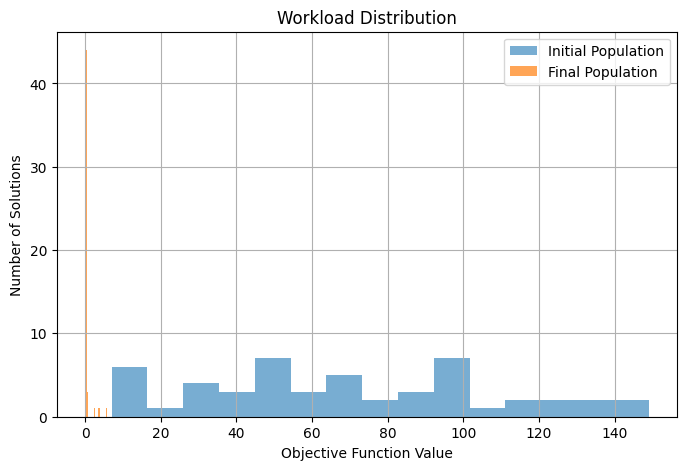

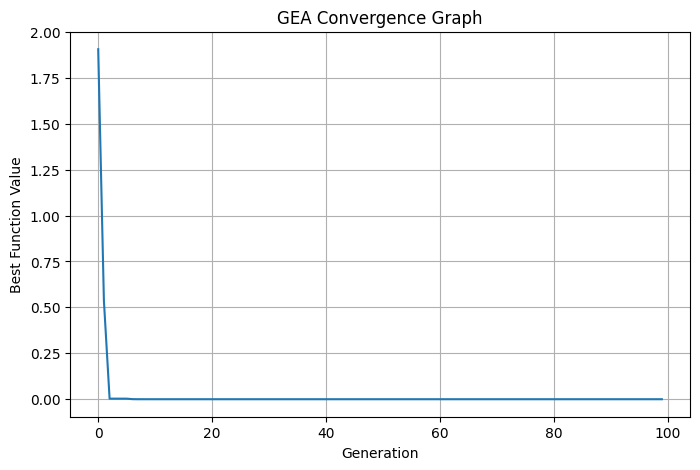

In [2]:

import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

POP_SIZE = 50
GENERATIONS = 100
MUTATION_RATE = 0.1
CROSSOVER_RATE = 0.8
BOUNDS = (-10, 10)

def objective(x, y):
    return x**2 + y**2

def express(gene):
    return gene[0], gene[1]

def fitness(gene):
    x, y = express(gene)
    return 1 / (1 + objective(x, y))

def select(population):
    candidates = random.sample(population, 3)
    return max(candidates, key=fitness)

def crossover(p1, p2):
    if random.random() < CROSSOVER_RATE:
        alpha = random.random()
        return [
            alpha * p1[0] + (1 - alpha) * p2[0],
            alpha * p1[1] + (1 - alpha) * p2[1]
        ]
    return p1[:]

def mutate(gene):
    for i in range(2):
        if random.random() < MUTATION_RATE:
            gene[i] += np.random.normal(0, 1)
            gene[i] = np.clip(gene[i], *BOUNDS)
    return gene

population = [
    [random.uniform(*BOUNDS), random.uniform(*BOUNDS)]
    for _ in range(POP_SIZE)
]

initial_values = [objective(*express(g)) for g in population]
best_history = []

for generation in range(GENERATIONS):
    new_population = []

    best = min(population, key=lambda g: objective(*express(g)))
    new_population.append(best[:])

    while len(new_population) < POP_SIZE:
        p1 = select(population)
        p2 = select(population)
        child = crossover(p1, p2)
        child = mutate(child)
        new_population.append(child)

    population = new_population

    best = min(population, key=lambda g: objective(*express(g)))
    best_history.append(objective(*express(best)))

best = min(population, key=lambda g: objective(*express(g)))
x, y = express(best)

final_values = [objective(*express(g)) for g in population]

print("Best Solution")
print("x =", round(x, 6))
print("y =", round(y, 6))
print("Minimum Function Value =", round(objective(x, y), 8))
print("Generations =", GENERATIONS)

plt.figure(figsize=(8, 5))
plt.hist(initial_values, bins=15, alpha=0.6, label="Initial Population")
plt.hist(final_values, bins=15, alpha=0.7, label="Final Population")
plt.xlabel("Objective Function Value")
plt.ylabel("Number of Solutions")
plt.title("Workload Distribution")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(best_history)
plt.xlabel("Generation")
plt.ylabel("Best Function Value")
plt.title("GEA Convergence Graph")
plt.grid()
plt.show()
